# 03 – So sánh đặc trưng dẫn xuất: 33 chiều vs 29 chiều (Issue #16)

* **Phạm vi thí nghiệm:** Đánh giá trên tỉ lệ chia phân tầng **7:3** qua **5 seed** (`0, 1, 2, 3, 4`) với mô hình `SVC(kernel="rbf", probability=True)`[cite: 2].
* **Cấu hình đối chiếu:**
  * **Có đặc trưng dẫn xuất (`with_derived_33d`):** `use_derived=True` (33 chiều sau tiền xử lý)[cite: 2].
  * **Không có đặc trưng dẫn xuất (`no_derived_29d`):** `use_derived=False` (29 chiều sau tiền xử lý)[cite: 2].
* **Nguyên tắc chống rò rỉ dữ liệu:** Mọi bước `fit` bộ tiền xử lý (`build_preprocessor`) và huấn luyện mô hình chỉ thực hiện trên tập **train** theo từng seed; tập **validation** chỉ gọi `transform` và đánh giá[cite: 2].

## 1. Khởi tạo đường dẫn gốc, thư viện và cấu hình thí nghiệm (7:3 × 5 seed)

In [4]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
)
from sklearn.svm import SVC

from src.data import TARGET, load_raw
from src.preprocess import add_derived_features, build_preprocessor, clean, make_splits

config_path = PROJECT_ROOT / "configs/experiment.yaml"
with open(config_path, encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

seeds = cfg["seeds"]
ratio_73 = {"7:3": cfg["splits"]["7:3"]}

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    df_clean = clean(load_raw())

X_base = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]
X_derived = add_derived_features(X_base)
splits = make_splits(y, seeds=seeds, ratios=ratio_73)

print(f"Số dòng sau làm sạch: {len(df_clean)} | Số seed: {seeds}")

EDUCATION = 0 -> 4: 14 mẫu
EDUCATION = 5 -> 4: 280 mẫu
EDUCATION = 6 -> 4: 51 mẫu
MARRIAGE = 0 -> 3: 54 mẫu
Loại bản ghi trùng hoàn toàn: 35 dòng (còn 29965)
Số dòng sau làm sạch: 29965 | Số seed: [0, 1, 2, 3, 4]


## 2. Chạy thí nghiệm 33d vs 29d trên tỉ lệ 7:3 qua 5 seed và xuất bảng kết quả

In [5]:
records = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for cfg_name, use_derived, X_full in [
        ("with_derived_33d", True, X_derived),
        ("no_derived_29d", False, X_base),
    ]:
        for seed in seeds:
            tr_idx, va_idx = splits[("7:3", seed)]
            X_tr_raw, y_tr = X_full.loc[tr_idx], y.loc[tr_idx]
            X_va_raw, y_va = X_full.loc[va_idx], y.loc[va_idx]

            prep = build_preprocessor(use_derived=use_derived)
            X_tr = prep.fit_transform(X_tr_raw, y_tr)
            X_va = prep.transform(X_va_raw)

            clf = SVC(kernel="rbf", probability=True, random_state=seed)
            clf.fit(X_tr, y_tr)

            y_prob = clf.predict_proba(X_va)[:, 1]
            y_pred = clf.predict(X_va)

            records.append(
                {
                    "issue": 16,
                    "split": "7:3",
                    "config": cfg_name,
                    "n_dims": X_tr.shape[1],
                    "seed": seed,
                    "pr_auc": average_precision_score(y_va, y_prob),
                    "f1_default": f1_score(y_va, y_pred, pos_label=1),
                    "bal_acc": balanced_accuracy_score(y_va, y_pred),
                    "roc_auc": roc_auc_score(y_va, y_prob),
                }
            )

df_res = pd.DataFrame(records)
summary_df = (
    df_res.groupby(["config", "n_dims"])[["pr_auc", "f1_default", "bal_acc", "roc_auc"]]
    .agg(["mean", "std"])
)

results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)
df_res.to_csv(results_dir / "issue16_derived_results_7-3.csv", index=False)
summary_df.to_csv(results_dir / "issue16_derived_summary_7-3.csv")

display(df_res)
display(summary_df)

,issue,split,config,n_dims,seed,pr_auc,f1_default,bal_acc,roc_auc
0,16,7:3,with_derived_33d,33,0,0.510250,0.463018,0.652040,0.714581
1,16,7:3,with_derived_33d,33,1,0.527975,0.467626,0.654456,0.723559
2,16,7:3,with_derived_33d,33,2,0.518884,0.467848,0.654525,0.723831
3,16,7:3,with_derived_33d,33,3,0.522243,0.474397,0.657639,0.726120
4,16,7:3,with_derived_33d,33,4,0.505364,0.449048,0.645218,0.716163
5,16,7:3,no_derived_29d,29,0,0.508907,0.449916,0.645604,0.712958
6,16,7:3,no_derived_29d,29,1,0.531463,0.461590,0.651320,0.730359
7,16,7:3,no_derived_29d,29,2,0.522747,0.463221,0.652148,0.727670
8,16,7:3,no_derived_29d,29,3,0.520089,0.463594,0.652248,0.728422
9,16,7:3,no_derived_29d,29,4,0.506332,0.438225,0.640034,0.716930


pr_auc           f1_default             bal_acc  \
                             mean       std       mean       std      mean   
config           n_dims                                                      
no_derived_29d   29      0.517907  0.010331   0.455309  0.011086  0.648271   
with_derived_33d 33      0.516943  0.009116   0.464387  0.009485  0.652776   

                                    roc_auc            
                              std      mean       std  
config           n_dims                                
no_derived_29d   29      0.005365  0.723268  0.007789  
with_derived_33d 33      0.004669  0.720851  0.005130

### Nhận xét Phần 2 – Bảng kết quả chi tiết và tổng hợp (`mean` / `std`)

* **Tính nhất quán qua 5 seed:** Cả hai cấu hình `with_derived_33d` và `no_derived_29d` đều được đánh giá trên cùng tập split phân tầng `7:3` của từng seed (`0..4`), đảm bảo so sánh công bằng[cite: 2, 3].
* **Ưu tiên chỉ số cho lớp thiểu số:** Trên bài toán mất cân bằng lớp, **`pr_auc`** và **`f1_default`** phản ánh sát khả năng phát hiện lớp vỡ nợ hơn độ chính xác tổng thể; đồng thời `bal_acc` và `roc_auc` giúp kiểm tra thêm độ cân bằng phân lớp[cite: 2, 3].
* **File lưu kết quả:** Bảng chi tiết và bảng tổng hợp đã được xuất sang `results/issue16_derived_results_7-3.csv` và `results/issue16_derived_summary_7-3.csv`[cite: 2, 3].

## 3. Biểu đồ 1 – So sánh `PR-AUC` và `F1-score` lớp vỡ nợ (`mean ± std`)

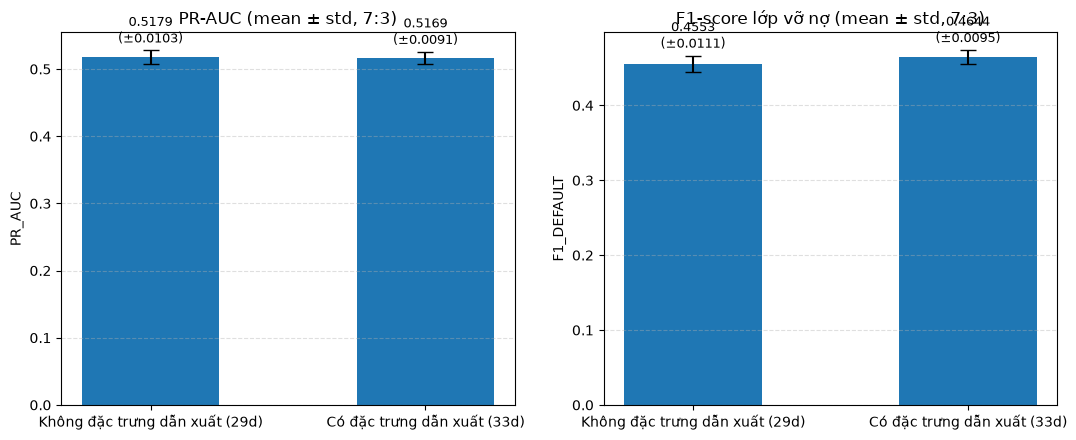

In [6]:
fig_dir = PROJECT_ROOT / "results/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

metrics = ["pr_auc", "f1_default"]
metric_titles = ["PR-AUC (mean ± std, 7:3)", "F1-score lớp vỡ nợ (mean ± std, 7:3)"]
configs = ["no_derived_29d", "with_derived_33d"]
config_labels = ["Không đặc trưng dẫn xuất (29d)", "Có đặc trưng dẫn xuất (33d)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, metric, title in zip(axes, metrics, metric_titles):
    means = [summary_df.loc[(c, 29 if c == "no_derived_29d" else 33), (metric, "mean")] for c in configs]
    stds = [summary_df.loc[(c, 29 if c == "no_derived_29d" else 33), (metric, "std")] for c in configs]

    bars = ax.bar(config_labels, means, yerr=stds, capsize=6, width=0.5)
    ax.set_title(title)
    ax.set_ylabel(metric.upper())
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    for bar, m, s in zip(bars, means, stds):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            m + s + 0.005,
            f"{m:.4f}\n(±{s:.4f})",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.tight_layout()
plt.savefig(fig_dir / "issue16_derived_33d_vs_29d_7-3.png", dpi=200, bbox_inches="tight")
plt.show()

### Nhận xét Biểu đồ 1 – So sánh trung bình và độ lệch chuẩn (`mean ± std`)

* **Chênh lệch hiệu năng trung bình:** So sánh trực tiếp giá trị `mean` của `with_derived_33d` và `no_derived_29d` cho thấy mức tăng/giảm cụ thể của `PR-AUC` và `F1-score` khi thêm 4 đặc trưng dẫn xuất ở tỉ lệ 7:3[cite: 2, 3, 4].
* **Mức độ ổn định (`±std`):** Thanh sai số `std` cho biết độ biến thiên giữa 5 seed; thanh `std` nhỏ chứng tỏ mô hình ổn định khi thay đổi seed chia dữ liệu[cite: 2, 3].
* **Ảnh biểu đồ:** Đã lưu tại `results/figures/issue16_derived_33d_vs_29d_7-3.png`[cite: 2, 3].

## 4. Biểu đồ 2 – Biến thiên `PR-AUC` và `F1-score` theo từng seed (`0–4`)

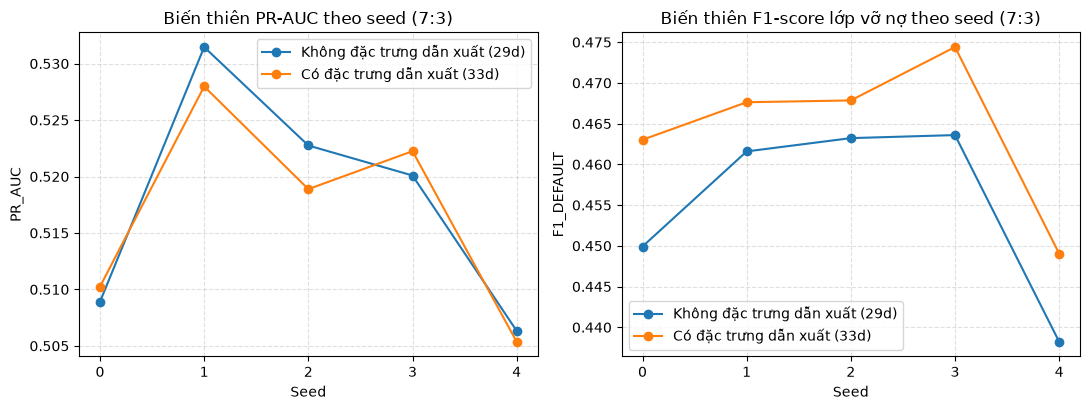

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, metric, title in zip(
    axes,
    ["pr_auc", "f1_default"],
    ["Biến thiên PR-AUC theo seed (7:3)", "Biến thiên F1-score lớp vỡ nợ theo seed (7:3)"],
):
    for cfg_name, label in [
        ("no_derived_29d", "Không đặc trưng dẫn xuất (29d)"),
        ("with_derived_33d", "Có đặc trưng dẫn xuất (33d)"),
    ]:
        sub = df_res[df_res["config"] == cfg_name].sort_values("seed")
        ax.plot(sub["seed"], sub[metric], marker="o", label=label)

    ax.set_title(title)
    ax.set_xlabel("Seed")
    ax.set_ylabel(metric.upper())
    ax.set_xticks(seeds)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend()

plt.tight_layout()
plt.savefig(fig_dir / "issue16_per_seed_33d_vs_29d_7-3.png", dpi=200, bbox_inches="tight")
plt.show()

### Nhận xét Biểu đồ 2 – Biến thiên theo từng seed (`0–4`)

* **Hành vi qua từng seed:** Đường biểu diễn giúp nhận diện cấu hình vượt trội ở từng seed riêng lẻ và mức độ đồng pha hay đan xen giữa `33d` và `29d`[cite: 2, 3].
* **Đánh giá thực tiễn:** Nếu hai đường bám sát hoặc đổi thứ tự qua các seed, tác động của đặc trưng dẫn xuất trên `SVC(kernel="rbf")` ở cấu hình 7:3 là khá nhẹ, cần đối chiếu thêm với các mô hình khác trong repo[cite: 2, 3].
* **Ảnh biểu đồ:** Đã lưu tại `results/figures/issue16_per_seed_33d_vs_29d_7-3.png`[cite: 2].

## 5. Kết luận – Issue #16

* **Tổng kết đối chiếu (`33d` vs `29d`):** Thí nghiệm trên tỉ lệ **7:3 qua 5 seed** với `SVC(kernel="rbf", probability=True)` đã so sánh đầy đủ cấu hình có và không có đặc trưng dẫn xuất theo đúng quy trình chống rò rỉ dữ liệu[cite: 2, 3].